In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [ ]:
uploaded = files.upload()

Saving cohort_data_raw.csv to cohort_data_raw.csv


In [ ]:
df = pd.read_csv('cohort_data_raw.csv')

In [ ]:
df['cohort_month'] = pd.to_datetime(df['cohort_month'])

In [ ]:
df1 = pd.pivot_table(data = df, index = 'cohort_month', columns = 'month_since_first_order', values = 'customer_count', aggfunc = 'sum')\
.fillna(0)
df1

month_since_first_order,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09-01,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2016-10-01,262.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,2.0,2.0
2016-12-01,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2017-01-01,717.0,2.0,2.0,1.0,3.0,1.0,3.0,1.0,1.0,0.0,3.0,1.0,5.0,3.0,1.0,1.0,2.0,3.0,1.0,0.0
2017-02-01,1628.0,3.0,5.0,2.0,7.0,2.0,4.0,3.0,2.0,3.0,2.0,5.0,2.0,3.0,2.0,1.0,1.0,3.0,0.0,0.0
2017-03-01,2503.0,11.0,9.0,10.0,9.0,4.0,4.0,8.0,8.0,2.0,9.0,3.0,5.0,3.0,4.0,6.0,2.0,3.0,0.0,0.0
2017-04-01,2256.0,14.0,5.0,4.0,6.0,6.0,8.0,7.0,7.0,4.0,6.0,2.0,1.0,1.0,2.0,2.0,3.0,0.0,0.0,0.0
2017-05-01,3451.0,16.0,16.0,10.0,10.0,11.0,14.0,5.0,9.0,9.0,9.0,12.0,8.0,1.0,6.0,7.0,0.0,0.0,0.0,0.0
2017-06-01,3037.0,15.0,12.0,13.0,9.0,12.0,11.0,7.0,4.0,6.0,9.0,11.0,5.0,5.0,7.0,0.0,0.0,0.0,0.0,0.0


In [ ]:

df2 = df[df['month_since_first_order'] == 0].loc[:, ['cohort_month', 'customer_count']].set_index('cohort_month')['customer_count']

In [ ]:
df3 = df1.div(df2, axis = 0)*100

Text(195.72222222222223, 0.5, 'Дата когорты')

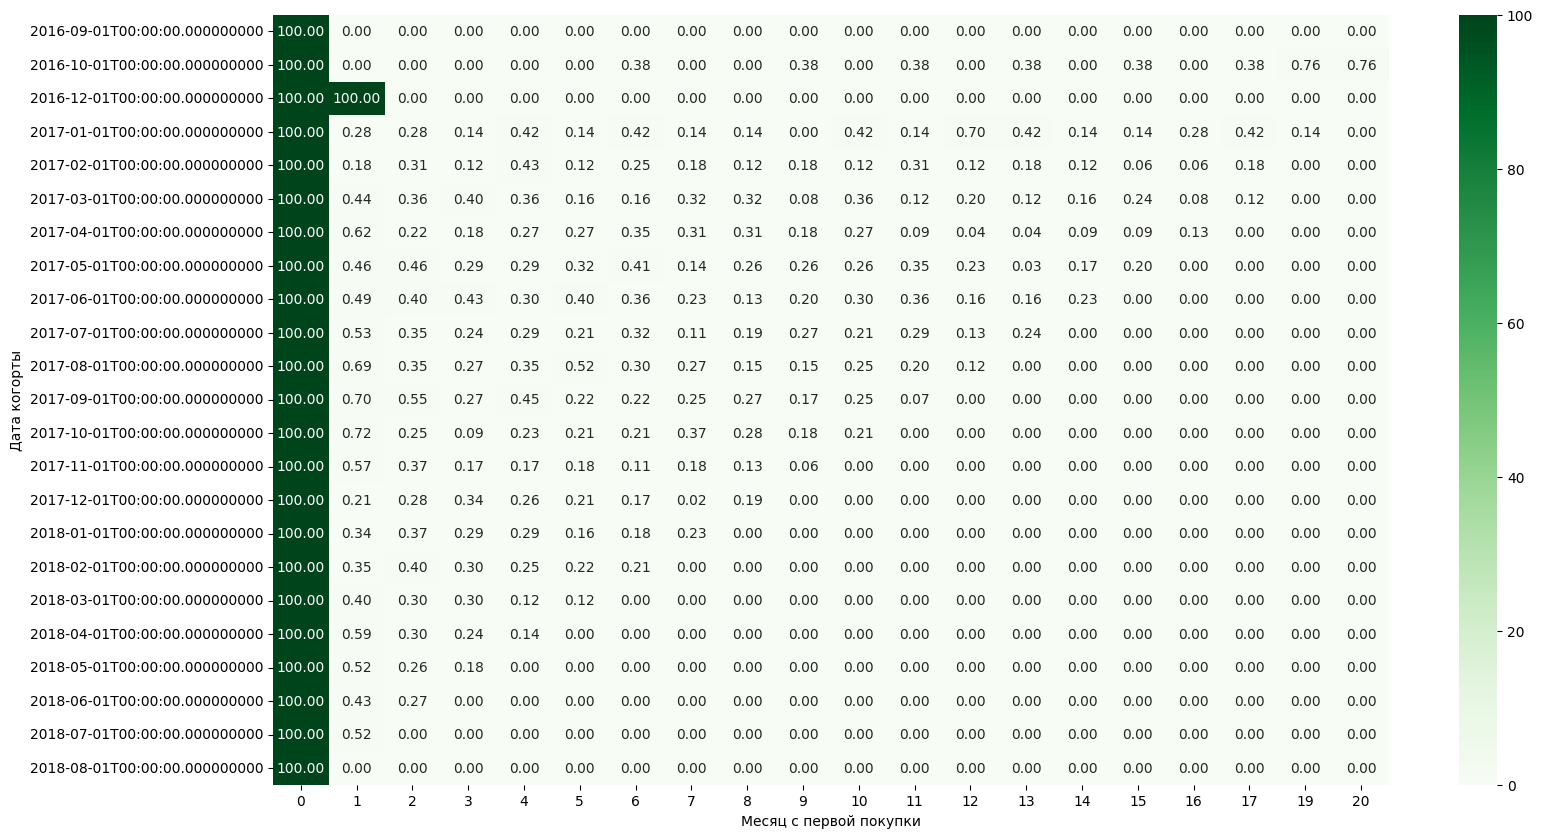

In [ ]:
plt.figure(figsize = (18,10))
sns.heatmap(data = df3, cmap = 'Greens', annot = True,  fmt = '.2f')
plt.xlabel('Месяц с первой покупки')
plt.ylabel('Дата когорты')

Retention падает почти до нуля уже после нулевого месяца (< 1% в большинстве ячеек)

В матрице нет строки за ноябрь 2016 — проверка в базе данных подтвердила, что в этом месяце не было ни одного заказа со статусом delivered, где клиент совершал бы первую покупку.

2016-12-01 - 1 клиент
